In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
PROCESSED_DIR = Path("../data/processed")
MASTER_FILE = PROCESSED_DIR / "air_pollution_weather_daily_master.parquet"

df = pd.read_parquet(MASTER_FILE)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["station_id", "date"]).reset_index(drop=True)

print(f"Rows: {len(df):,} | Stations: {df['station_id'].nunique()}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")


Rows: 12,271 | Stations: 6
Date range: 2016-12-11 to 2025-12-31


In [3]:
TARGETS = ["pm25", "pm10"]

overall_missingness_df = pd.DataFrame({
    "pollutant": TARGETS,
    "total_rows": [len(df)] * len(TARGETS),
    "available_days": [df[t].notna().sum() for t in TARGETS],
    "missing_days": [df[t].isna().sum() for t in TARGETS],
})
overall_missingness_df["available_percent"] = (
    overall_missingness_df["available_days"] / overall_missingness_df["total_rows"] * 100
).round(2)

display(overall_missingness_df)


,pollutant,total_rows,available_days,missing_days,available_percent
0,pm25,12271,3990,8281,32.52
1,pm10,12271,8891,3380,72.46


In [4]:
print("Missing-data policy: complete-case deletion, no imputation.")
print("- targets are never imputed: regression values and high-pollution labels would be model-fabricated")
print("- lag/rolling features require real history; imputed history would leak into evaluation")
print("- weather comes from the Open-Meteo reanalysis merged on date; rows with missing weather are dropped, not interpolated")
print("- cost is quantified per stage: missing-target rows above; lag-history loss and final modelling rows are printed in 06 and 07/08")
print(f"- master rows: {len(df):,} | missing PM2.5: {df['pm25'].isna().sum():,} | missing PM10: {df['pm10'].isna().sum():,}")


Missing-data policy: complete-case deletion, no imputation.
- targets are never imputed: regression values and high-pollution labels would be model-fabricated
- lag/rolling features require real history; imputed history would leak into evaluation
- weather comes from the Open-Meteo reanalysis merged on date; rows with missing weather are dropped, not interpolated
- cost is quantified per stage: missing-target rows above; lag-history loss and final modelling rows are printed in 06 and 07/08
- master rows: 12,271 | missing PM2.5: 8,281 | missing PM10: 3,380


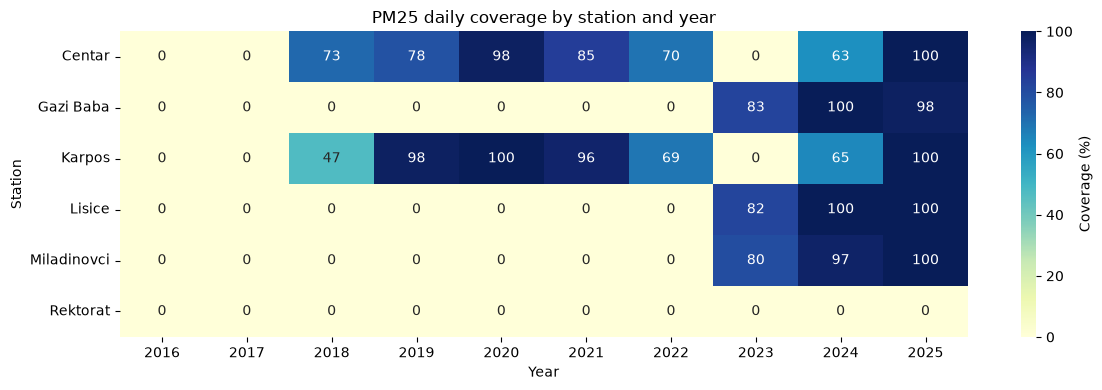

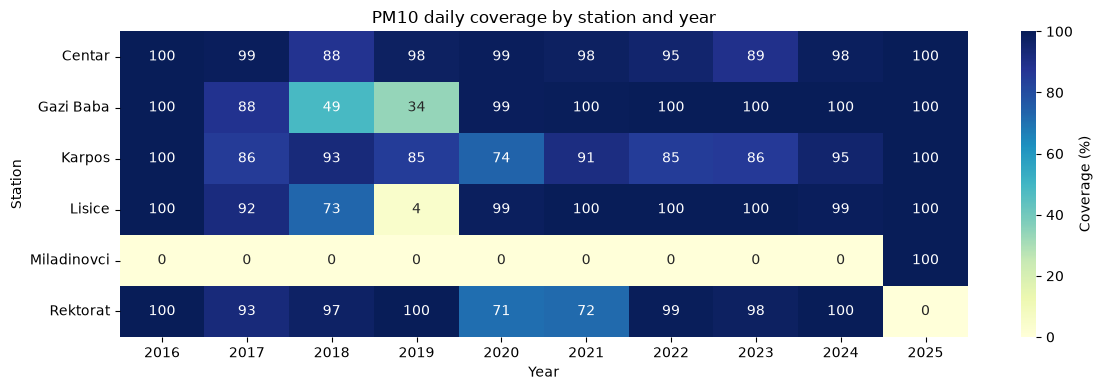

In [5]:
yearly_parts = []

for target in TARGETS:
    part = (
        df.assign(year=df["date"].dt.year, available=df[target].notna())
        .groupby(["station_id", "station_name", "year"], as_index=False)
        .agg(total_days=("date", "size"), available_days=("available", "sum"))
    )
    part["pollutant"] = target
    part["coverage_percent"] = (part["available_days"] / part["total_days"] * 100).round(2)
    yearly_parts.append(part)

yearly_coverage_df = pd.concat(yearly_parts, ignore_index=True)

for target in TARGETS:
    matrix = (
        yearly_coverage_df[yearly_coverage_df["pollutant"] == target]
        .pivot(index="station_name", columns="year", values="coverage_percent")
        .sort_index()
    )

    plt.figure(figsize=(12, 4))
    sns.heatmap(matrix, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100,
                cbar_kws={"label": "Coverage (%)"})
    plt.title(f"{target.upper()} daily coverage by station and year")
    plt.xlabel("Year")
    plt.ylabel("Station")
    plt.tight_layout()
    plt.show()


In [6]:
MIN_VALID_DAYS = 365
MIN_YEARS_WITH_DATA = 2
MIN_DAYS_IN_YEAR = 90

selection_parts = []

for target in TARGETS:
    target_df = df[["station_id", "station_name", "date", target]].copy()
    target_df["year"] = target_df["date"].dt.year
    target_df["available"] = target_df[target].notna()

    overall = (
        target_df.groupby(["station_id", "station_name"], as_index=False)
        .agg(
            total_days=("date", "size"),
            valid_days=("available", "sum"),
            first_valid_date=("date", lambda s: s[target_df.loc[s.index, "available"]].min()),
            last_valid_date=("date", lambda s: s[target_df.loc[s.index, "available"]].max()),
        )
    )

    yearly = (
        target_df.groupby(["station_id", "station_name", "year"], as_index=False)
        .agg(valid_days_in_year=("available", "sum"))
    )
    years_ok = (
        yearly[yearly["valid_days_in_year"] >= MIN_DAYS_IN_YEAR]
        .groupby(["station_id", "station_name"], as_index=False)
        .agg(years_with_enough_data=("year", "nunique"))
    )

    result = overall.merge(years_ok, on=["station_id", "station_name"], how="left")
    result["years_with_enough_data"] = result["years_with_enough_data"].fillna(0).astype(int)
    result["coverage_percent"] = (result["valid_days"] / result["total_days"] * 100).round(2)
    result["target"] = target

    selected = (
        (result["valid_days"] >= MIN_VALID_DAYS)
        & (result["years_with_enough_data"] >= MIN_YEARS_WITH_DATA)
    )
    result["decision"] = "exclude"
    result.loc[selected, "decision"] = "include"

    selection_parts.append(result)

station_selection_df = pd.concat(selection_parts, ignore_index=True).sort_values(
    ["target", "decision", "station_name"]
).reset_index(drop=True)

display(station_selection_df)


,station_id,station_name,total_days,valid_days,first_valid_date,last_valid_date,years_with_enough_data,coverage_percent,target,decision
0,2978,Miladinovci,2088,93,2025-09-19,2025-12-31,1,4.45,pm10,exclude
1,2996,Centar,2011,1928,2016-12-11,2025-12-31,9,95.87,pm10,include
2,2919,Gazi Baba,2104,1733,2016-12-11,2025-12-31,9,82.37,pm10,include
3,2977,Karpos,2081,1811,2016-12-11,2025-12-31,9,87.03,pm10,include
4,2976,Lisice,2067,1672,2016-12-11,2025-12-31,8,80.89,pm10,include
5,2979,Rektorat,1920,1654,2016-12-11,2024-08-25,7,86.15,pm10,include
6,2979,Rektorat,1920,0,NaT,NaT,0,0.00,pm25,exclude
7,2996,Centar,2011,1284,2018-03-07,2025-12-31,7,63.85,pm25,include
8,2919,Gazi Baba,2104,463,2023-06-27,2025-12-31,3,22.01,pm25,include
9,2977,Karpos,2081,1334,2018-03-07,2025-12-31,7,64.10,pm25,include


In [7]:
included_station_ids = {
    target: station_selection_df.loc[
        (station_selection_df["target"] == target) & (station_selection_df["decision"] == "include"),
        "station_id",
    ].tolist()
    for target in TARGETS
}

for target, ids in included_station_ids.items():
    names = station_selection_df.loc[
        (station_selection_df["target"] == target) & (station_selection_df["decision"] == "include"),
        "station_name",
    ].tolist()
    print(f"{target.upper()} included stations: {names} ({ids})")


PM25 included stations: ['Centar', 'Gazi Baba', 'Karpos', 'Lisice', 'Miladinovci'] ([2996, 2919, 2977, 2976, 2978])
PM10 included stations: ['Centar', 'Gazi Baba', 'Karpos', 'Lisice', 'Rektorat'] ([2996, 2919, 2977, 2976, 2979])


In [8]:
duplicate_rows = df.duplicated(subset=["station_id", "date"]).sum()
print(f"Duplicate (station_id, date) rows: {duplicate_rows}")


Duplicate (station_id, date) rows: 0


In [9]:
for target in TARGETS:
    print(f"\n{target.upper()} summary (valid days only):")
    display(df[target].describe())



PM25 summary (valid days only):


count    3990.000000
mean       24.353210
std        21.200134
min         0.000000
25%        10.705833
50%        17.939891
75%        29.656250
max       253.738889
Name: pm25, dtype: float64


PM10 summary (valid days only):


count    8891.000000
mean       48.676488
std        39.437662
min         0.000000
25%        25.533333
50%        36.691304
75%        56.435088
max       435.681818
Name: pm10, dtype: float64

In [10]:
for target in TARGETS:
    hours_col = f"{target}_observed_hours"
    if hours_col in df.columns:
        valid_mask = df[target].notna()
        print(f"\n{target.upper()} observed_hours (valid days only):")
        display(df.loc[valid_mask, hours_col].describe())



PM25 observed_hours (valid days only):


count    3990.000000
mean       23.085464
std         1.558089
min        18.000000
25%        23.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: pm25_observed_hours, dtype: float64


PM10 observed_hours (valid days only):


count    8891.000000
mean       23.011135
std         1.626133
min        18.000000
25%        22.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: pm10_observed_hours, dtype: float64

In [11]:
for target in TARGETS:
    print(f"\nTop 10 highest {target.upper()} values:")
    display(
        df.nlargest(10, target)[
            ["station_id", "station_name", "date", target, f"{target}_observed_hours"]
        ]
    )



Top 10 highest PM25 values:


,station_id,station_name,date,pm25,pm25_observed_hours
4680,2977,Karpos,2019-01-18,253.738889,18.0
4681,2977,Karpos,2019-01-20,163.857143,21.0
6239,2977,Karpos,2025-12-19,156.043478,23.0
6238,2977,Karpos,2025-12-18,146.545455,22.0
10730,2996,Centar,2019-01-27,143.936364,22.0
4991,2977,Karpos,2020-01-25,140.058333,24.0
6240,2977,Karpos,2025-12-20,139.434783,23.0
4971,2977,Karpos,2020-01-04,138.462500,24.0
4679,2977,Karpos,2019-01-17,136.740909,22.0
4687,2977,Karpos,2019-01-27,133.268182,22.0



Top 10 highest PM10 values:


,station_id,station_name,date,pm10,pm10_observed_hours
2104,2976,Lisice,2016-12-11,435.681818,22.0
4393,2977,Karpos,2017-12-14,397.315789,19.0
2322,2976,Lisice,2018-01-01,383.947368,19.0
4680,2977,Karpos,2019-01-18,349.944444,18.0
10442,2996,Centar,2017-12-14,348.526316,19.0
8340,2979,Rektorat,2016-12-11,342.850000,20.0
2329,2976,Lisice,2018-01-08,335.571429,21.0
0,2919,Gazi Baba,2016-12-11,334.590909,22.0
8580,2979,Rektorat,2018-01-29,330.700000,20.0
2110,2976,Lisice,2016-12-18,325.181818,22.0


In [12]:
both_valid = df[df["pm25"].notna() & df["pm10"].notna()].copy()
violations = (both_valid["pm10"] < both_valid["pm25"]).sum()
print(f"Rows where PM10 < PM2.5 (should be rare/zero): {violations} out of {len(both_valid)}")

if violations > 0:
    violation_df = both_valid.loc[
        both_valid["pm10"] < both_valid["pm25"],
        ["station_id", "station_name", "date", "pm25", "pm10"]
    ].assign(diff=lambda x: x["pm25"] - x["pm10"]).sort_values("date", ascending=True)

    display(violation_df)

    print(f"Max diff (pm25 - pm10): {violation_df['diff'].max()}")


Rows where PM10 < PM2.5 (should be rare/zero): 171 out of 3445


,station_id,station_name,date,pm25,pm10,diff
4506,2977,Karpos,2018-05-30,51.010000,36.585000,14.425000
4554,2977,Karpos,2018-08-07,59.309091,42.247826,17.061265
4555,2977,Karpos,2018-08-08,58.830435,42.756522,16.073913
4556,2977,Karpos,2018-08-09,58.576190,40.185714,18.390476
10639,2996,Centar,2018-09-24,82.687500,76.086667,6.600833
...,...,...,...,...,...,...
8331,2978,Miladinovci,2025-12-23,83.982609,50.990909,32.991700
6244,2977,Karpos,2025-12-24,63.854167,59.925000,3.929167
6245,2977,Karpos,2025-12-25,18.038261,16.634783,1.403478
8336,2978,Miladinovci,2025-12-28,70.852381,30.530000,40.322381


Max diff (pm25 - pm10): 94.51624999999999


In [13]:
LARGE_DIFF_THRESHOLD = 10

large_violation_df = (
    df.loc[
        df["pm25"].notna()
        & df["pm10"].notna()
        & (df["pm10"] < df["pm25"]),
        [
            "station_id",
            "station_name",
            "date",
            "pm25",
            "pm10",
            "pm25_observed_hours",
            "pm10_observed_hours",
        ],
    ]
    .assign(diff=lambda x: x["pm25"] - x["pm10"])
    .query("diff > @LARGE_DIFF_THRESHOLD")
    .sort_values("diff", ascending=False)
)

print(f"Large violations (PM2.5 - PM10 > {LARGE_DIFF_THRESHOLD}): {len(large_violation_df)}")
display(large_violation_df)


Large violations (PM2.5 - PM10 > 10): 34


,station_id,station_name,date,pm25,pm10,pm25_observed_hours,pm10_observed_hours,diff
6153,2977,Karpos,2024-08-07,113.779167,19.262917,24.0,24.0,94.516250
3901,2976,Lisice,2024-01-23,60.375000,12.000000,24.0,23.0,48.375000
11673,2996,Centar,2022-07-09,66.729167,19.518333,24.0,24.0,47.210833
11655,2996,Centar,2022-06-11,63.975000,19.137500,24.0,24.0,44.837500
6154,2977,Karpos,2024-08-08,68.925000,24.666667,24.0,24.0,44.258333
3900,2976,Lisice,2024-01-22,53.391667,12.000000,24.0,24.0,41.391667
8336,2978,Miladinovci,2025-12-28,70.852381,30.530000,21.0,20.0,40.322381
8331,2978,Miladinovci,2025-12-23,83.982609,50.990909,23.0,22.0,32.991700
5410,2977,Karpos,2021-10-09,42.170833,12.341667,24.0,24.0,29.829167
5670,2977,Karpos,2022-08-14,34.471304,10.708261,23.0,23.0,23.763043


In [14]:
display(large_violation_df["pm10_observed_hours"].describe())

print("\nPM10 observed-hour counts for large violations:")
display(
    large_violation_df["pm10_observed_hours"]
    .value_counts(dropna=False)
    .sort_index()
)


count    34.000000
mean     23.235294
std       1.349721
min      19.000000
25%      23.000000
50%      24.000000
75%      24.000000
max      24.000000
Name: pm10_observed_hours, dtype: float64


PM10 observed-hour counts for large violations:


pm10_observed_hours
19.0     1
20.0     2
21.0     1
22.0     2
23.0     6
24.0    22
Name: count, dtype: int64

In [15]:
normal_pm10_days = df.loc[
    df["pm10"].notna() & ~(
        df["pm25"].notna()
        & df["pm10"].notna()
        & (df["pm10"] < df["pm25"])
        & ((df["pm25"] - df["pm10"]) > LARGE_DIFF_THRESHOLD)
    ),
    "pm10_observed_hours",
]

coverage_comparison = pd.DataFrame({
    "large_pm10_lt_pm25_violations": large_violation_df["pm10_observed_hours"].describe(),
    "other_valid_pm10_days": normal_pm10_days.describe(),
})

display(coverage_comparison)


,large_pm10_lt_pm25_violations,other_valid_pm10_days
count,34.000000,8857.000000
mean,23.235294,23.010274
std,1.349721,1.627107
min,19.000000,18.000000
25%,23.000000,22.000000
50%,24.000000,24.000000
75%,24.000000,24.000000
max,24.000000,24.000000


In [16]:
df["pm_violation_diff"] = df["pm25"] - df["pm10"]
df["large_pm10_lt_pm25_flag"] = (
    df["pm25"].notna()
    & df["pm10"].notna()
    & (df["pm10"] < df["pm25"])
    & (df["pm_violation_diff"] > LARGE_DIFF_THRESHOLD)
)

print(f"Rows flagged as large PM2.5 > PM10: {df['large_pm10_lt_pm25_flag'].sum():,}")


Rows flagged as large PM2.5 > PM10: 34


In [17]:
pm25_selected_df = (
    df[df["station_id"].isin(included_station_ids["pm25"]) & df["pm25"].notna()]
    .sort_values(["station_id", "date"])
    .reset_index(drop=True)
)

pm10_selected_df = (
    df[df["station_id"].isin(included_station_ids["pm10"]) & df["pm10"].notna()]
    .sort_values(["station_id", "date"])
    .reset_index(drop=True)
)

print(f"PM2.5 selected rows: {len(pm25_selected_df):,}")
print(f"PM10 selected rows: {len(pm10_selected_df):,}")


PM2.5 selected rows: 3,990
PM10 selected rows: 8,798


In [18]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

station_selection_df.to_parquet(PROCESSED_DIR / "station_selection_report.parquet", index=False)
df.to_parquet(PROCESSED_DIR / "daily_air_quality_cleaned.parquet", index=False)
pm25_selected_df.to_parquet(PROCESSED_DIR / "pm25_selected_station_days.parquet", index=False)
pm10_selected_df.to_parquet(PROCESSED_DIR / "pm10_selected_station_days.parquet", index=False)


In [19]:
print(f"Saved {len(df):,} rows and {len(df.columns)} columns")
print(f"Station selection report saved with {len(station_selection_df):,} rows")
print(f"PM2.5 selected: {len(pm25_selected_df):,} rows | PM10 selected: {len(pm10_selected_df):,} rows")


Saved 12,271 rows and 77 columns
Station selection report saved with 12 rows
PM2.5 selected: 3,990 rows | PM10 selected: 8,798 rows
